# British Airways: Customer Booking Prediction

**Goal:** Predict whether a customer will **complete a flight booking**, and identify which factors drive that decision, so marketing can target customers and markets most likely to convert.

**Dataset:** 50,000 customer booking records (`customer_booking.csv`), 13 features + target `booking_complete`.

**Contents**
1. Data loading & inspection
2. Exploratory data analysis
3. Feature engineering
4. Model training (Random Forest, stratified cross-validation)
5. Test-set evaluation & feature importance
6. Conclusions

---

## 1. Data loading & inspection

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("customer_booking.csv", encoding="ISO-8859-1")
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


The `.head()` method allows us to view the first 5 rows in the dataset, this is useful for visual inspection of our columns

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  str    
 2   trip_type              50000 non-null  str    
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  str    
 7   route                  50000 non-null  str    
 8   booking_origin         50000 non-null  str    
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), str(5)
memory usage: 5.3 MB


The `.info()` method gives us a data description, telling us the names of the columns, their data types and how many null values we have. Fortunately, we have no null values. It looks like some of these columns should be converted into different data types, e.g. flight_day.

To provide more context, below is a more detailed data description, explaining exactly what each column means:

- `num_passengers` = number of passengers travelling
- `sales_channel` = sales channel booking was made on
- `trip_type` = trip Type (Round Trip, One Way, Circle Trip)
- `purchase_lead` = number of days between travel date and booking date
- `length_of_stay` = number of days spent at destination
- `flight_hour` = hour of flight departure
- `flight_day` = day of week of flight departure
- `route` = origin -> destination flight route
- `booking_origin` = country from where booking was made
- `wants_extra_baggage` = if the customer wanted extra baggage in the booking
- `wants_preferred_seat` = if the customer wanted a preferred seat in the booking
- `wants_in_flight_meals` = if the customer wanted in-flight meals in the booking
- `flight_duration` = total duration of flight (in hours)
- `booking_complete` = flag indicating if the customer completed the booking

Before we compute any statistics on the data, lets do any necessary data conversion

In [4]:
df["flight_day"].unique()

<StringArray>
['Sat', 'Wed', 'Thu', 'Mon', 'Sun', 'Tue', 'Fri']
Length: 7, dtype: str

In [5]:
mapping = {
    "Mon": 1,
    "Tue": 2,
    "Wed": 3,
    "Thu": 4,
    "Fri": 5,
    "Sat": 6,
    "Sun": 7,
}

df["flight_day"] = df["flight_day"].map(mapping)

In [6]:
df["flight_day"].unique()

array([6, 3, 4, 1, 7, 2, 5])

In [7]:
df.describe()

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,3.814420,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,1.992792,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,1.000000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,2.000000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,4.000000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,5.000000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,7.000000,1.000000,1.000000,1.000000,9.500000,1.000000


The `.describe()` method summarises the numeric columns. `purchase_lead` and `length_of_stay` are heavily right-skewed (long tails up to 867 and 778 days), and only ~15% of sessions end in a completed booking, so the target is imbalanced.

## 2. Exploratory data analysis

Next, I look at how the booking rate varies across numeric features, categories, routes, booking origins and add-on preferences.

In [8]:

import numpy as np

df = pd.read_csv("customer_booking.csv", encoding="latin-1")

# --- Basic shape/target check ---
print(df.shape)
print(df['booking_complete'].value_counts(normalize=True))

# --- Numeric feature distributions vs target ---
numeric_cols = ['num_passengers', 'purchase_lead', 'length_of_stay',
                 'flight_hour', 'flight_duration']
print(df.groupby('booking_complete')[numeric_cols].mean())

# --- Look for outliers/skew in purchase_lead and length_of_stay ---
print(df[['purchase_lead', 'length_of_stay']].describe(percentiles=[.5, .9, .95, .99]))

# --- Categorical feature: booking rate by category ---
for col in ['sales_channel', 'trip_type', 'flight_day']:
    print(f"\n--- {col} ---")
    print(df.groupby(col)['booking_complete'].agg(['mean', 'count']))

# --- High-cardinality categoricals: top values by volume + conversion rate ---
for col in ['route', 'booking_origin']:
    print(f"\n--- {col} (top 15 by volume) ---")
    top = df[col].value_counts().head(15).index
    print(df[df[col].isin(top)].groupby(col)['booking_complete'].agg(['mean', 'count']).sort_values('count', ascending=False))

# --- Binary "wants_*" flags vs target ---
for col in ['wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals']:
    print(f"\n--- {col} ---")
    print(df.groupby(col)['booking_complete'].mean())

# --- Correlation matrix (numeric only, quick sanity check) ---
print(df[numeric_cols + ['wants_extra_baggage','wants_preferred_seat','wants_in_flight_meals','booking_complete']].corr()['booking_complete'].sort_values(ascending=False))

(50000, 14)
booking_complete
0    0.85044
1    0.14956
Name: proportion, dtype: float64
                  num_passengers  purchase_lead  length_of_stay  flight_hour  \
booking_complete                                                               
0                       1.580923      85.779926       23.647218     9.050162   
1                       1.649906      80.167157       19.617679     9.158331   

                  flight_duration  
booking_complete                   
0                        7.344266  
1                        6.898258  
       purchase_lead  length_of_stay
count   50000.000000     50000.00000
mean       84.940480        23.04456
std        90.451378        33.88767
min         0.000000         0.00000
50%        51.000000        17.00000
90%       224.000000        53.00000
95%       287.000000        84.00000
99%       390.000000       168.00000
max       867.000000       778.00000

--- sales_channel ---
                   mean  count
sales_channel          

**EDA takeaways:** booking origin and route show the biggest differences in conversion (e.g. Malaysia ~34% vs. Australia ~5%), while day of week barely matters. Customers who want extras (baggage, seats, meals) convert slightly more often, and shorter flights convert better.

## 3. Feature engineering

- Split `route` into origin and destination airport codes
- `total_extras_wanted`, `is_last_minute` (booked < 7 days ahead), `is_weekend_flight`, `long_trip` (stay > 30 days)
- Train/test split **before** encoding to avoid leakage
- Frequency-encode high-cardinality columns (route, booking origin, airports), fit on train only
- One-hot encode low-cardinality columns (sales channel, trip type, flight day)

In [9]:

from sklearn.model_selection import train_test_split

df = pd.read_csv("customer_booking.csv", encoding="latin-1")

# --- 1. Split origin/destination airport codes out of route (6-letter codes) ---
df['route_origin'] = df['route'].str[:3]
df['route_dest'] = df['route'].str[3:]

# --- 2. Engineered features ---
df['total_extras_wanted'] = (df['wants_extra_baggage'] +
                              df['wants_preferred_seat'] +
                              df['wants_in_flight_meals'])
df['is_last_minute'] = (df['purchase_lead'] < 7).astype(int)
df['is_weekend_flight'] = df['flight_day'].isin(['Sat', 'Sun']).astype(int)
df['long_trip'] = (df['length_of_stay'] > 30).astype(int)

# --- 3. Train/test split FIRST (before any frequency/target encoding, to avoid leakage) ---
X = df.drop(columns=['booking_complete'])
y = df['booking_complete']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# --- 4. Frequency-encode high-cardinality categoricals (route, booking_origin, route_origin, route_dest) ---
# fit counts on TRAIN only, then map onto both train and test
def freq_encode(train_col, test_col):
    freq_map = train_col.value_counts(normalize=True)
    return train_col.map(freq_map).fillna(0), test_col.map(freq_map).fillna(0)

for col in ['route', 'booking_origin', 'route_origin', 'route_dest']:
    X_train[col + '_freq'], X_test[col + '_freq'] = freq_encode(X_train[col], X_test[col])

# --- 5. One-hot encode low-cardinality categoricals ---
low_card_cols = ['sales_channel', 'trip_type', 'flight_day']
X_train = pd.get_dummies(X_train, columns=low_card_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=low_card_cols, drop_first=True)

# align columns (in case a category shows up in one split but not the other)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

# --- 6. Drop original high-cardinality text columns now that we've encoded them ---
X_train = X_train.drop(columns=['route', 'booking_origin', 'route_origin', 'route_dest'])
X_test = X_test.drop(columns=['route', 'booking_origin', 'route_origin', 'route_dest'])

print(X_train.shape, X_test.shape)
print(X_train.dtypes)
print(X_train.head())

(40000, 25) (10000, 25)
num_passengers             int64
purchase_lead              int64
length_of_stay             int64
flight_hour                int64
wants_extra_baggage        int64
wants_preferred_seat       int64
wants_in_flight_meals      int64
flight_duration          float64
total_extras_wanted        int64
is_last_minute             int64
is_weekend_flight          int64
long_trip                  int64
route_freq               float64
booking_origin_freq      float64
route_origin_freq        float64
route_dest_freq          float64
sales_channel_Mobile        bool
trip_type_OneWay            bool
trip_type_RoundTrip         bool
flight_day_Mon              bool
flight_day_Sat              bool
flight_day_Sun              bool
flight_day_Thu              bool
flight_day_Tue              bool
flight_day_Wed              bool
dtype: object
       num_passengers  purchase_lead  length_of_stay  flight_hour  \
11179               2            168              38            8   

## 4. Model training: Random Forest

A Random Forest with capped depth and minimum leaf size (to limit overfitting) and `class_weight='balanced'` for the 85/15 imbalance, validated with 5-fold stratified cross-validation.

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

# cast booleans to int for safety/consistency
bool_cols = X_train.select_dtypes(include='bool').columns
X_train[bool_cols] = X_train[bool_cols].astype(int)
X_test[bool_cols] = X_test[bool_cols].astype(int)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,          # cap depth to reduce overfitting given the noisy/weak features
    min_samples_leaf=20,   # avoid tiny leaves memorizing noise
    class_weight='balanced',  # correct for the 85/15 imbalance
    random_state=42,
    n_jobs=-1
)

# --- 5-fold stratified cross-validation on the TRAINING set ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_auc = cross_val_score(rf, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
cv_scores_f1 = cross_val_score(rf, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)

print("CV ROC-AUC scores:", cv_scores_auc)
print("Mean CV ROC-AUC:", cv_scores_auc.mean().round(4), "+/-", cv_scores_auc.std().round(4))
print("CV F1 scores:", cv_scores_f1)
print("Mean CV F1:", cv_scores_f1.mean().round(4), "+/-", cv_scores_f1.std().round(4))

# --- Fit final model on full training set ---
rf.fit(X_train, y_train)

CV ROC-AUC scores: [0.77305561 0.76068229 0.76642822 0.77325449 0.77030712]
Mean CV ROC-AUC: 0.7687 +/- 0.0047
CV F1 scores: [0.41578706 0.39789618 0.40583675 0.40695811 0.41145951]
Mean CV F1: 0.4076 +/- 0.006


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

## 5. Evaluation on the held-out test set & feature importance

Test ROC-AUC: 0.7766

              precision    recall  f1-score   support

  No Booking       0.94      0.66      0.78      8504
     Booking       0.28      0.76      0.41      1496

    accuracy                           0.68     10000
   macro avg       0.61      0.71      0.60     10000
weighted avg       0.84      0.68      0.72     10000


Confusion matrix:
[[5639 2865]
 [ 356 1140]]

booking_origin_freq      0.386402
route_dest_freq          0.106695
length_of_stay           0.087770
route_freq               0.087310
route_origin_freq        0.072921
flight_duration          0.065776
purchase_lead            0.042781
total_extras_wanted      0.031374
wants_extra_baggage      0.026953
flight_hour              0.023536
sales_channel_Mobile     0.014693
wants_preferred_seat     0.012944
num_passengers           0.007405
long_trip                0.006836
wants_in_flight_meals    0.006280
is_weekend_flight        0.003261
flight_day_Wed           0.002514
is_last_minute           0

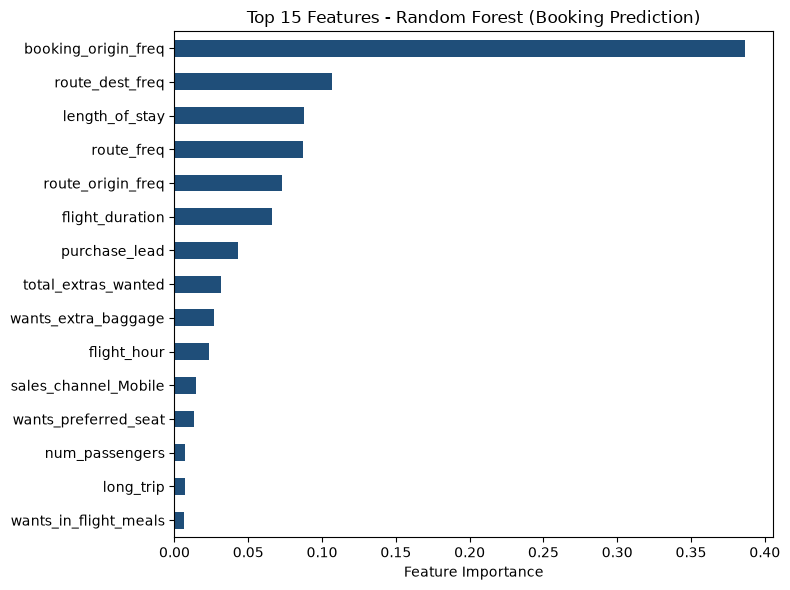

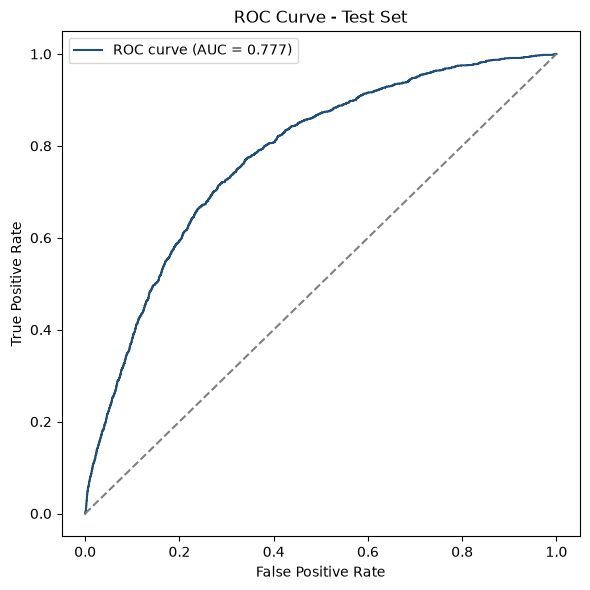

In [13]:
from sklearn.metrics import (roc_auc_score, classification_report, confusion_matrix,
                              precision_recall_curve, roc_curve)
import matplotlib.pyplot as plt
import numpy as np

# --- Predict on test set ---
y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

print("Test ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))
print()
print(classification_report(y_test, y_pred, target_names=['No Booking', 'Booking']))
print()
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

# --- Feature importance ---
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print()
print(importances)

# --- Plot feature importance ---
fig, ax = plt.subplots(figsize=(8, 6))
importances.head(15).sort_values().plot(kind='barh', ax=ax, color='#1f4e79')
ax.set_xlabel('Feature Importance')
ax.set_title('Top 15 Features - Random Forest (Booking Prediction)')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

# --- ROC curve ---
fpr, tpr, _ = roc_curve(y_test, y_proba)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc_score(y_test, y_proba):.3f})', color='#1f4e79')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve - Test Set')
ax.legend()
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150)
plt.show()

## 6. Conclusions

| Metric | Result |
|---|---|
| Cross-validated ROC-AUC | 0.769 ± 0.005 |
| Test ROC-AUC | **0.777** (vs. 0.50 random) |
| Recall on bookings | **76%** of true bookers correctly flagged |
| Precision on bookings | 28% |

- **Geography drives the predictions.** Booking origin and route-related features account for roughly two-thirds of the model's feature importance.
- **Trip details matter less:** length of stay, flight duration and purchase lead contribute moderately, while day of week, trip type and individual add-ons contribute very little.
- **Recommendation:** focus proactive marketing on high-converting origin markets and routes rather than on trip attributes.
- **Next steps:** tune the decision threshold for the business's precision/recall trade-off, try gradient boosting (e.g. XGBoost/LightGBM), and add time-based features.